# Generate observations configuration

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Edit the `observations` dict below (one entry per instrument).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in the case JSON with the saved file path.

In [1]:
from utils.config import PATHS, resolve
from utils.observation import onshore_sites as obs
from utils.viz import case_plots as plot

## Parameters

In [2]:
from utils.config import ONSHORE_WAVES

# Output file — defaults to the path declared in the case config ("onshore_waves").
output_observations_file = ONSHORE_WAVES
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Observations/NewSouthWales_observations.json
AoI      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/AoI_Polygons/NewSouthWales_AoI.shp
topobathy: /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/GEBCO/NewSouthWales_GEBCO.tiff


## Observations dict

Edit the dictionary below. Keys are unique `instrument_id` strings.

Required per entry:
- `lon`, `lat` — WGS84 coordinates
- `type` — role used downstream (`validation`, `waves`, `spectrum`, `calibration`, `levels`, `ignore`, …)
- `institution` — data provider (e.g. `IMOS`, `NDBC`, `SPREP`)
- `recording` — approximate coverage period as a string (e.g. `"2010-2024"`)

Optional:
- `depth` — water depth in metres (`null` if unknown)
- `name` — human-readable station name
- `role` — overrides `type` when filtering by role in later notebooks
- any extra property (e.g. `msl` for tide gauges) is kept in the GeoJSON

In [ ]:
observations: dict[str, dict] = {
    # --- Offshore MHL Waverider buoys (Manly Hydraulics Laboratory, NSW deepwater network) ---
    # Coordinates are deployment-area centroids from AODN/researchdata.edu.au metadata records
    # (buoys are redeployed within a small watch circle across their multi-decade history).
    "Sydney_Buoy": {
        "lon": 151.4126,
        "lat": -33.7733,
        "type": "waves",
        "institution": "MHL",
        "recording": "1992-2017",
        "depth": -85.0,
        "name": "Sydney offshore Waverider buoy (WAVESYD)",
    },
    "PortKembla_Buoy": {
        "lon": 150.9833,
        "lat": -34.4667,
        "type": "waves",
        "institution": "MHL",
        "recording": "1976-2017",
        "depth": -75.0,
        "name": "Port Kembla offshore Waverider buoy (WAVEPOK, KEM)",
    },
    "CrowdyHead_Buoy": {
        "lon": 152.8575,
        "lat": -31.815,
        "type": "waves",
        "institution": "MHL",
        "recording": "1985-2017",
        "depth": -80.0,
        "name": "Crowdy Head offshore Waverider buoy (WAVECRH, CRO)",
    },
    "CoffsHarbour_Buoy": {
        "lon": 153.265,
        "lat": -30.375,
        "type": "waves",
        "institution": "MHL",
        "recording": "1976-2017",
        "depth": -70.0,
        "name": "Coffs Harbour offshore Waverider buoy (WAVECOH, COH)",
    },
    "ByronBay_Buoy": {
        "lon": 153.7,
        "lat": -28.75,
        "type": "waves",
        "institution": "MHL",
        "recording": "1976-2017",
        "depth": -65.0,
        "name": "Byron Bay offshore Waverider buoy (WAVEBYB, BYR)",
    },
    "Eden_Buoy": {
        "lon": 150.0972,
        "lat": -37.1591,
        "type": "waves",
        "institution": "MHL",
        "recording": "2012-2017",
        "depth": -100.0,
        "name": "Eden offshore Waverider buoy (WAVEEDN, EDE)",
    },
    "BatemansBay_Buoy": {
        "lon": 150.338,
        "lat": -35.73,
        "type": "waves",
        "institution": "MHL",
        "recording": "1986-2015",
        "depth": -75.0,
        "name": "Batemans Bay offshore Waverider buoy (WAVEBAB, BAT)",
    },
    # --- Nearshore Spotter wave buoys (NSW DCCEEW / SEED nearshore wave buoy program) ---
    "Farquhar_Buoy": {
        "lon": 152.63301,
        "lat": -31.93132,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2018-08-16 to 2019-03-12",
        "depth": -12.31,
        "name": "Farquhar nearshore wave buoy",
    },
    "OldBarA_Buoy": {
        "lon": 152.59317,
        "lat": -31.98063,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2018-08-16 to 2018-12-04",
        "depth": -12.53,
        "name": "OldBarA nearshore wave buoy",
    },
    "OldBarB_Buoy": {
        "lon": 152.59238,
        "lat": -31.98135,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2018-10-03 to 2019-03-11",
        "depth": -12.97,
        "name": "OldBarB nearshore wave buoy",
    },
    "BoomerangA_Buoy": {
        "lon": 152.54684,
        "lat": -32.34228,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-03-21 to 2019-06-04",
        "depth": -11.45,
        "name": "BoomerangA nearshore wave buoy",
    },
    "BoomerangA2_Buoy": {
        "lon": 152.54759,
        "lat": -32.34284,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-07-24 to 2020-05-20",
        "depth": -13.29,
        "name": "BoomerangA2 nearshore wave buoy",
    },
    "BoomerangB_Buoy": {
        "lon": 152.55802,
        "lat": -32.34791,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-03-21 to 2019-06-18",
        "depth": -33.03,
        "name": "BoomerangB nearshore wave buoy",
    },
    "BoomerangB2_Buoy": {
        "lon": 152.55781,
        "lat": -32.34831,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-07-24 to 2020-01-16",
        "depth": -32.85,
        "name": "BoomerangB2 nearshore wave buoy",
    },
    "Worimi_Buoy": {
        "lon": 151.82245,
        "lat": -32.87583,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-12-06 to 2020-02-26",
        "depth": -13.62,
        "name": "Worimi nearshore wave buoy",
    },
    "Stockton_Buoy": {
        "lon": 151.79869,
        "lat": -32.90213,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-12-06 to 2021-04-09",
        "depth": -13.16,
        "name": "Stockton nearshore wave buoy",
    },
    "Narrabeen_Buoy": {
        "lon": 151.30467,
        "lat": -33.7188,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-03-02 to 2016-05-17",
        "depth": -12.4,
        "name": "Narrabeen nearshore wave buoy",
    },
    "Collaroy_Buoy": {
        "lon": 151.30596,
        "lat": -33.72705,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-03-02 to 2016-05-17",
        "depth": -13.17,
        "name": "Collaroy nearshore wave buoy",
    },
    "Collaroy2_Buoy": {
        "lon": 151.30605,
        "lat": -33.72691,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-06-03 to 2016-07-21",
        "depth": -13.32,
        "name": "Collaroy2 nearshore wave buoy",
    },
    "Collaroy3_Buoy": {
        "lon": 151.30593,
        "lat": -33.7263,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2019-10-21 to 2020-03-31",
        "depth": -13.62,
        "name": "Collaroy3 nearshore wave buoy",
    },
    "Collaroy4_Buoy": {
        "lon": 151.30732,
        "lat": -33.72702,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2020-03-31 to 2021-11-02",
        "depth": -15.21,
        "name": "Collaroy4 nearshore wave buoy",
    },
    "Collaroy5_Buoy": {
        "lon": 151.30665,
        "lat": -33.72657,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2021-12-21 to 2023-08-31",
        "depth": -14.52,
        "name": "Collaroy5 nearshore wave buoy",
    },
    "Bronte_Buoy": {
        "lon": 151.27455,
        "lat": -33.90477,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-08-11 to 2016-10-26",
        "depth": -13.56,
        "name": "Bronte nearshore wave buoy",
    },
    "Maroubra_Buoy": {
        "lon": 151.26297,
        "lat": -33.94991,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-08-11 to 2016-10-26",
        "depth": -13.64,
        "name": "Maroubra nearshore wave buoy",
    },
    "Deeban_Buoy": {
        "lon": 151.1539,
        "lat": -34.07866,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2021-06-30 to 2021-12-07",
        "depth": -6.02,
        "name": "Deeban nearshore wave buoy",
    },
    "Deeban2_Buoy": {
        "lon": 151.15379,
        "lat": -34.07849,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2022-03-01 to 2022-11-16",
        "depth": -6.1,
        "name": "Deeban2 nearshore wave buoy",
    },
    "Figure8Pools_Buoy": {
        "lon": 151.05012,
        "lat": -34.19984,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2016-12-06 to 2017-12-18",
        "depth": -29.96,
        "name": "Figure8Pools nearshore wave buoy",
    },
    "Woonona_Buoy": {
        "lon": 150.92628,
        "lat": -34.35491,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2017-06-05 to 2017-10-30",
        "depth": -13.62,
        "name": "Woonona nearshore wave buoy",
    },
    "FairyMeadow_Buoy": {
        "lon": 150.91225,
        "lat": -34.3971,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2017-06-05 to 2017-10-30",
        "depth": -14.52,
        "name": "FairyMeadow nearshore wave buoy",
    },
    "Gerroa_Buoy": {
        "lon": 150.80965,
        "lat": -34.81436,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2018-06-13 to 2018-07-27",
        "depth": -30.46,
        "name": "Gerroa nearshore wave buoy",
    },
    "Broulee_Buoy": {
        "lon": 150.18879,
        "lat": -35.84837,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2020-11-10 to 2021-08-24",
        "depth": -13.18,
        "name": "Broulee nearshore wave buoy",
    },
    "Broulee2_Buoy": {
        "lon": 150.18879,
        "lat": -35.84779,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2021-11-19 to 2022-11-24",
        "depth": -12.75,
        "name": "Broulee2 nearshore wave buoy",
    },
    "Bengello_Buoy": {
        "lon": 150.1612,
        "lat": -35.87995,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2020-11-10 to 2023-06-09",
        "depth": -12.81,
        "name": "Bengello nearshore wave buoy",
    },
    "Merimbula_Buoy": {
        "lon": 149.91653,
        "lat": -36.9086,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2020-11-16 to 2021-05-10",
        "depth": -13.09,
        "name": "Merimbula nearshore wave buoy",
    },
    "Merimbula2_Buoy": {
        "lon": 149.91662,
        "lat": -36.90841,
        "type": "waves",
        "institution": "NSW DCCEEW",
        "recording": "2021-05-10 to 2022-11-23",
        "depth": -13.01,
        "name": "Merimbula2 nearshore wave buoy",
    },
}

## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,depth,name,lon,lat
instrument_id,,,,,,,
Sydney_Buoy,waves,MHL,1992-2017,-85.00,Sydney offshore Waverider buoy (WAVESYD),151.41260,-33.77330
PortKembla_Buoy,waves,MHL,1976-2017,-75.00,"Port Kembla offshore Waverider buoy (WAVEPOK, ...",150.98330,-34.46670
CrowdyHead_Buoy,waves,MHL,1985-2017,-80.00,"Crowdy Head offshore Waverider buoy (WAVECRH, ...",152.85750,-31.81500
CoffsHarbour_Buoy,waves,MHL,1976-2017,-70.00,Coffs Harbour offshore Waverider buoy (WAVECOH...,153.26500,-30.37500
ByronBay_Buoy,waves,MHL,1976-2017,-65.00,"Byron Bay offshore Waverider buoy (WAVEBYB, BYR)",153.70000,-28.75000
Eden_Buoy,waves,MHL,2012-2017,-100.00,"Eden offshore Waverider buoy (WAVEEDN, EDE)",150.09720,-37.15910
BatemansBay_Buoy,waves,MHL,1986-2015,-75.00,"Batemans Bay offshore Waverider buoy (WAVEBAB,...",150.33800,-35.73000
Farquhar_Buoy,waves,NSW DCCEEW,2018-08-16 to 2019-03-12,-12.31,Farquhar nearshore wave buoy,152.63301,-31.93132
OldBarA_Buoy,waves,NSW DCCEEW,2018-08-16 to 2018-12-04,-12.53,OldBarA nearshore wave buoy,152.59317,-31.98063


## Map

(<Figure size 900x700 with 2 Axes>,
 <Axes: title={'center': 'NewSouthWales — Case observations'}, xlabel='longitude', ylabel='latitude'>)

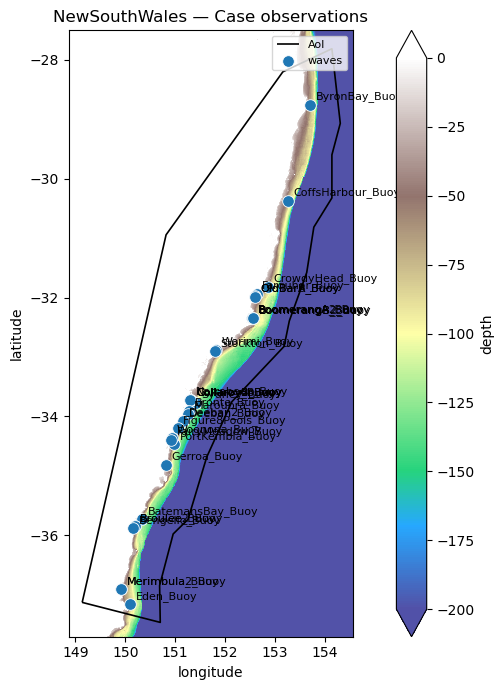

In [5]:
plot.plot_case_map(obs.dict_to_gdf(observations), title="Case observations")

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 35 feature(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Observations/NewSouthWales_observations.json


## Update the case JSON

After saving, add or update this key in the case JSON so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/<Case>_observations.json"
```

Use the exact relative path you set in `output_observations_file`.